# S3 - Trustworthy Machine-Learning Baselines (Final Deliverable)

> **Section 3: Trustworthy Machine-Learning Baselines** (instructor materials: `sections/s03/guide.md` & `sections/s03/homework.md`)
> This notebook consolidates the Day 1/2/3 working files and covers the full homework: task definition, data audit, train/test split, dummy baselines, linear regression (cross-validation + deliberate leakage experiment), logistic-regression classification evaluation, generalization evidence summary, the three critical questions, and the Codex review.
> Run it from the repository root; **Restart Kernel and Run All** must complete without errors.

## 1. Task definition (Fixed Experiment Contract)

- **Regression target:** `HOMO_LUMO_Gap_eV` (band gap, in eV); the unit of observation is one computed polymer record.
- **Classification task:** build a binary label `high_gap` (1 = high gap) using the training-set band-gap median as the threshold.
- **Honest features:** 13 numeric properties minus {`id`, the target, `HOMO_eV`, `LUMO_eV`} = 10 predictors.

Exclusions: `id` is an identifier, not a property; `HOMO_LUMO_Gap_eV` is the target itself; `HOMO_eV` and `LUMO_eV` jointly determine the target exactly (`LUMO - HOMO`, verified in §9) and would leak the answer.

## 2. Environment and data loading

Load the data from a repository-relative path and import all required libraries.

In [1]:
# Fix the working directory to the repository root so that all relative paths
# are computed from the repo root, regardless of which directory the kernel starts in.
import os
cwd = os.getcwd()
root = cwd
for _ in range(6):
    if os.path.isdir(os.path.join(root, "sections")):
        break
    parent = os.path.dirname(root)
    if parent == root:
        break
    root = parent
os.chdir(root)
print("Current cwd:", os.getcwd())

# 1. Import the libraries
import pandas as pd                  # tabular data handling
import numpy as np                   # numeric computation
import matplotlib.pyplot as plt      # plotting
import seaborn as sns                # nicer statistical plots
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score)             # split + CV
from sklearn.pipeline import Pipeline                  # preprocessing + model
from sklearn.preprocessing import StandardScaler       # z-score standardization
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier  # simple baselines
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

# 2. Load the CSV using a repository-relative path
df = pd.read_csv("sections/s02/homework/openpoly_calculated_properties.csv")
print("Data shape:", df.shape)   # (1000, 23): 1000 rows, 23 columns

Current cwd: /home/administrator/course


Data shape: (1000, 23)


In [2]:
# Define the 13 numeric property columns (reused from S2)
property_cols = df.select_dtypes(include=["float64", "int64"]).columns.tolist()
property_cols.remove("id")
print("13 numeric property columns:", property_cols)

# Define the target column
target = "HOMO_LUMO_Gap_eV"

# Honest features: the 13 numeric columns minus the target and the two leaky columns
honest_feats = [c for c in property_cols
                if c != target and c not in ("HOMO_eV", "LUMO_eV")]
print(f"\nNumber of honest features: {len(honest_feats)}")
print("Honest features:", honest_feats)

13 numeric property columns: ['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'HOMO_eV', 'LUMO_eV', 'Inner_energy_correction_Hatree', 'Thermal_correction_to_Enthalpy_Hatree', 'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree', 'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree', 'HOMO_LUMO_Gap_eV']

Number of honest features: 10
Honest features: ['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'Inner_energy_correction_Hatree', 'Thermal_correction_to_Enthalpy_Hatree', 'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree', 'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree']


## 3. Data audit and cleaning (the exact modeling rows)

In [3]:
# Validity rule: exclude Energy_Hatree == 0
raw_rows = len(df)
invalid_mask = df["Energy_Hatree"] == 0
removed = int(invalid_mask.sum())
valid = df[~invalid_mask].copy()
print(f"Raw rows: {raw_rows}")
print(f"Removed (Energy_Hatree==0): {removed}")
print(f"Retained (valid): {len(valid)}")

# Show target distribution on valid rows
print("\nTarget (HOMO_LUMO_Gap_eV) descriptive statistics on valid rows:")
print(valid[target].describe())

Raw rows: 1000
Removed (Energy_Hatree==0): 74
Retained (valid): 926

Target (HOMO_LUMO_Gap_eV) descriptive statistics on valid rows:
count    926.000000
mean       8.308145
std        0.481351
min        4.468900
25%        8.022225
50%        8.339550
75%        8.612650
max       10.001000
Name: HOMO_LUMO_Gap_eV, dtype: float64


### Cleaning rationale

Rows with `Energy_Hatree == 0` are treated as failed/unphysical calculations (energy cannot be zero) and filtered out in code: 74 rows are removed from the original 1000, leaving 926 valid modeling rows. This column is a placeholder/missing marker.

This choice is consistent with the Section 2 audit finding that `Energy_Hatree == 0` rows are placeholder/missing entries.

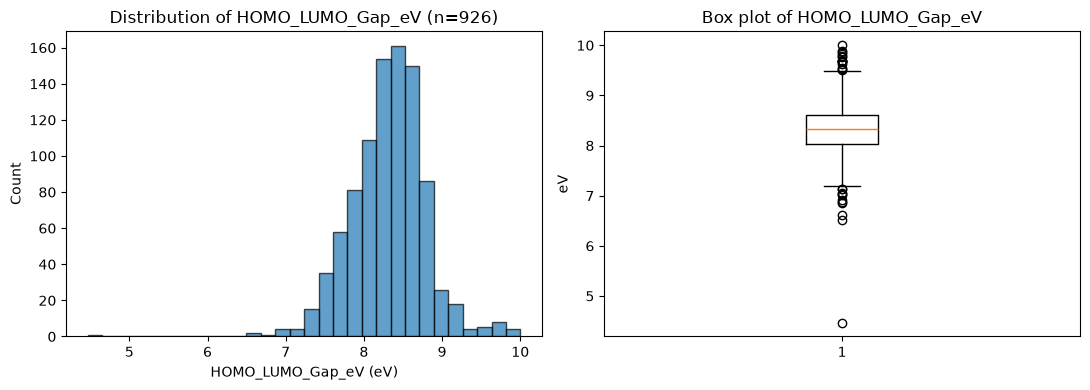

In [4]:
# ============ Target distribution: histogram + boxplot ============
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Histogram
axes[0].hist(valid[target], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title(f"Distribution of HOMO_LUMO_Gap_eV (n={len(valid)})")
axes[0].set_xlabel("HOMO_LUMO_Gap_eV (eV)")
axes[0].set_ylabel("Count")

# Boxplot
axes[1].boxplot(valid[target], orientation="vertical")
axes[1].set_title("Box plot of HOMO_LUMO_Gap_eV")
axes[1].set_ylabel("eV")

plt.tight_layout()
plt.show()

## 4. Train/test split and classification label (shared by both tasks)

In [5]:
# ============ Split: index-only, shared by regression and classification ============
valid_idx = valid.index.values                      # original row ids of the 926 valid samples
train_idx, test_idx = train_test_split(
    valid_idx,
    test_size=0.2,
    random_state=42,
)
# Sort for readability (does not affect the result)
train_idx = np.sort(train_idx)
test_idx  = np.sort(test_idx)

print(f"Total valid samples: {len(valid_idx)}")
print(f"Train rows: {len(train_idx)}  ({(len(train_idx)/len(valid_idx))*100:.0f}%)")
print(f"Test rows: {len(test_idx)} ({len(test_idx)/len(valid_idx)*100:.0f}%)")
print(f"Train/test overlap: {len(set(train_idx) & set(test_idx))} overlapping (should be 0)")

Total valid samples: 926
Train rows: 740  (80%)
Test rows: 186 (20%)
Train/test overlap: 0 overlapping (should be 0)


In [6]:
# Slice the data by the split indices (features X and target y separated)
train = valid.loc[train_idx]
test  = valid.loc[test_idx]

X_train = train[honest_feats]   # only the 10 honest features
y_train = train[target]         # regression target (numeric)

X_test  = test[honest_feats]
y_test  = test[target]

print("X_train shape:", X_train.shape)   # (~740, 10)
print("X_test shape :", X_test.shape)    # (~186, 10)

X_train shape: (740, 10)
X_test shape : (186, 10)


In [7]:
# ============ Classification label: training-median gap threshold ============
train_median = y_train.median()      # training rows only; do not touch the test set
print(f"Training median gap (classification threshold): {train_median:.4f} eV")

# Build the high/low labels
y_train_cls = (train[target] >= train_median).astype(int)  # high_gap = 1
y_test_cls  = (test[target]  >= train_median).astype(int)

print("\nTraining-set class distribution:")
print(y_train_cls.value_counts())
print("\nTest-set class distribution:")
print(y_test_cls.value_counts())

Training median gap (classification threshold): 8.3323 eV

Training-set class distribution:
HOMO_LUMO_Gap_eV
1    370
0    370
Name: count, dtype: int64

Test-set class distribution:
HOMO_LUMO_Gap_eV
1    102
0     84
Name: count, dtype: int64


In [8]:
# ============ Predictor data table: dtypes / missing / range (on valid modeling rows) ============
pred_info = pd.DataFrame({
    "dtype": valid[honest_feats].dtypes.astype(str),
    "n_nonnull": valid[honest_feats].notna().sum(),
    "min": valid[honest_feats].min(),
    "max": valid[honest_feats].max(),
    "std": valid[honest_feats].std(),
})
print(f"Predictor table on the {len(valid)} valid modeling rows (features n={len(honest_feats)}):")
print(pred_info.round(6).to_string())

Predictor table on the 926 valid modeling rows (features n=10):
                                                  dtype  n_nonnull          min         max          std
Energy_Hatree                                   float64        926 -9263.852166 -892.230383  1243.862577
es                                              float64        926     0.512693    0.999748     0.068707
Isotropic_Polarizability_au                     float64        926    -0.036470  674.733350    60.413470
Inner_energy_correction_Hatree                  float64        926     0.172873    3.446429     0.300974
Thermal_correction_to_Enthalpy_Hatree           float64        926     0.000944    0.000944     0.000000
Thermal_correction_to_Gibbs_Free_Energy_Hatree  float64        926     0.116903    0.632778     0.076719
Entropy_Hatree                                  float64        926     0.056915    0.123350     0.009237
Dipole_Debye                                    float64        926     0.464339   13.996553     

## 5. Predictor-to-target correlation audit (Pearson / Spearman)

In [9]:
# ============ Correlations (on the valid modeling rows) ============
# Combine features + target
audit = valid[honest_feats + [target]]

pearson_corr = audit.corr(method="pearson")[target].sort_values(ascending=False)
spearman_corr = audit.corr(method="spearman")[target].sort_values(ascending=False)

print("=== Pearson correlation with the gap (descending) ===")
print(pearson_corr.round(3))
print("\n=== Spearman correlation with the gap (descending) ===")
print(spearman_corr.round(3))

print("\n=== Pearson vs Spearman difference (may reveal nonlinearity) ===")
diff = (pearson_corr - spearman_corr).abs().sort_values(ascending=False)
print(diff.round(3))

=== Pearson correlation with the gap (descending) ===
HOMO_LUMO_Gap_eV                                  1.000
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.078
Entropy_Hatree                                    0.034
Gibbs_Free_Energy_Hatree                          0.013
Energy_Hatree                                     0.013
Enthalpy_Hatree                                   0.013
Inner_energy_correction_Hatree                   -0.000
Dipole_Debye                                     -0.052
es                                               -0.131
Isotropic_Polarizability_au                      -0.228
Thermal_correction_to_Enthalpy_Hatree               NaN
Name: HOMO_LUMO_Gap_eV, dtype: float64

=== Spearman correlation with the gap (descending) ===
HOMO_LUMO_Gap_eV                                  1.000
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.081
Entropy_Hatree                                    0.064
Inner_energy_correction_Hatree                    0.053
Enthalpy_Ha

### Correlation analysis

> **Which features correlate most strongly with the gap?** By absolute correlation:
> - `Isotropic_Polarizability_au`: Pearson **-0.228** (strongest)
> - `es`: **-0.131**
> - `Dipole_Debye`: **-0.052**
> - All remaining honest features are weakly correlated (|r| < 0.08).
> - Note: `Thermal_correction_to_Enthalpy_Hatree` is **constant** across all 926 valid rows (std=0), so its correlation is NaN - it is a constant column with no predictive information (an audit finding).
>
> **Do any features differ strongly between Pearson and Spearman?** No - the largest gap is only about 0.05 (`Inner_energy_correction_Hatree` at 0.054, `Entropy_Hatree` at 0.031), with the rest below 0.023. This indicates no strongly nonlinear-but-monotonic relationship with the gap was detected.
>
> More importantly, the strongest correlation is only about |0.21|. All honest features are weakly related to the gap, which **explains why the honest linear-regression test R2 is only ~0.25**: the features themselves are only weakly informative, or the real predictive signal does not lie in these ten computed properties (the gap likely depends more on molecular structure, which would require structural features or a neural network to explore).

## 6. Dummy baselines (minimum bar)

In [10]:
# ============ Dummy regression baseline (always predicts the mean) ============
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_train, y_train)
y_pred_dummy_reg = dummy_reg.predict(X_test)

print("=== Dummy regression (always predicts the training mean) ===")
print("Train R2 :", round(r2_score(y_train, dummy_reg.predict(X_train)), 4))
print("Test R2:", round(r2_score(y_test, y_pred_dummy_reg), 4))
print("Test MAE:", round(mean_absolute_error(y_test, y_pred_dummy_reg), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_dummy_reg)), 4))

=== Dummy regression (always predicts the training mean) ===
Train R2 : 0.0
Test R2: -0.0001
Test MAE: 0.3565
Test RMSE: 0.5216


In [11]:
# ============ Dummy classification baseline (always predicts the majority class) ============
dummy_clf = DummyClassifier(strategy="prior")
dummy_clf.fit(X_train, y_train_cls)
y_pred_dummy_clf = dummy_clf.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
print("=== Dummy classification (always predicts the majority class) ===")
print("Test Accuracy:", round(accuracy_score(y_test_cls, y_pred_dummy_clf), 4))
print("Test F1     :", round(f1_score(y_test_cls, y_pred_dummy_clf), 4))
print("Test ROC_AUC(prob):", round(roc_auc_score(y_test_cls, dummy_clf.predict_proba(X_test)[:,1]), 4))

=== Dummy classification (always predicts the majority class) ===
Test Accuracy: 0.4516
Test F1     : 0.0
Test ROC_AUC(prob): 0.5


## 7. Honest linear-regression baseline

Use a `StandardScaler + LinearRegression` pipeline and first run 5-fold `KFold` cross-validation on the training set.

In [12]:
# ============ 5-fold cross-validation: training set only ============
# The StandardScaler inside the pipeline is refit on each fold's training 4/5 only; validation 1/5 never participates - this is what keeps it clean
model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression()),
])

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# R2: higher is better, use directly
cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2")

# RMSE: sklearn maximizes scores, so RMSE is returned negated; negate back to the real RMSE
cv_rmse = -cross_val_score(model, X_train, y_train, cv=kf,
                           scoring="neg_root_mean_squared_error")

print("=== 5-fold cross-validation (training set only) ===")
print("Per-fold R2  :", [round(v, 4) for v in cv_r2])
print(f"R2  mean: {cv_r2.mean():.4f}   std: {cv_r2.std():.4f}")
print()
print("Per-fold RMSE:", [round(v, 4) for v in cv_rmse])
print(f"RMSE mean: {cv_rmse.mean():.4f}   std: {cv_rmse.std():.4f}")

=== 5-fold cross-validation (training set only) ===
Per-fold R2  : [np.float64(0.1575), np.float64(0.1999), np.float64(0.1862), np.float64(0.2139), np.float64(0.2375)]
R2  mean: 0.1990   std: 0.0268

Per-fold RMSE: [np.float64(0.4382), np.float64(0.4261), np.float64(0.3986), np.float64(0.4433), np.float64(0.3956)]
RMSE mean: 0.4204   std: 0.0198


### Cross-validation interpretation

For the honest linear regression on the training set, a 5-fold CV (`KFold(n_splits=5, shuffle=True, random_state=42)`) gives fold R2 between 0.158 and 0.238 (mean 0.199, std 0.027) and RMSE mean 0.420 (std 0.020). The fold-to-fold spread is moderate and relatively stable (std is about 13.5% of the mean), indicating the model is fairly stable across data subsets rather than driven by one lucky fold.

**Reporting only the mean is insufficient.** Two models can share the same mean while one is stable across folds and the other fluctuates wildly; the mean alone cannot distinguish them. The fold values (or the standard deviation) must be reported together to show the spread.

**Interpretive power for the test-set conclusion.** The CV R2 mean (0.199) is close to the test R2 (0.2494), though the test value lies slightly above the upper end of the fold range (0.238) and above "mean + 1 std" (~0.226). Agreement with CV therefore only establishes **consistency**, not that a single test score is fully "reliable" or insensitive to extreme samples. A more careful statement: the test score is consistent with the CV level and can serve as a reference for generalization, but must be further checked against residuals and extreme samples (see below).

## 8. Regression test evaluation

Fit once on all training rows, then evaluate R2/MAE/MSE/RMSE on the test set, with plots and error inspection.

In [13]:
# ============ Fit on all training rows ============
model.fit(X_train, y_train)          # training set only

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ---- Summarize the 4 train/test metrics in one table ----
def reg_metrics(y_true, y_pred):
    return {
        "R²":  r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),  # newer sklearn: use sqrt, not squared=False
    }

summary = pd.DataFrame({
    "Train": reg_metrics(y_train, y_pred_train),
    "Test" : reg_metrics(y_test,  y_pred_test),
}).round(4)
print("=== Honest linear regression: Train vs Test (4 metrics) ===")
print(summary)

=== Honest linear regression: Train vs Test (4 metrics) ===
       Train    Test
R²    0.2105  0.2494
MAE   0.3122  0.3011
MSE   0.1747  0.2042
RMSE  0.4179  0.4519


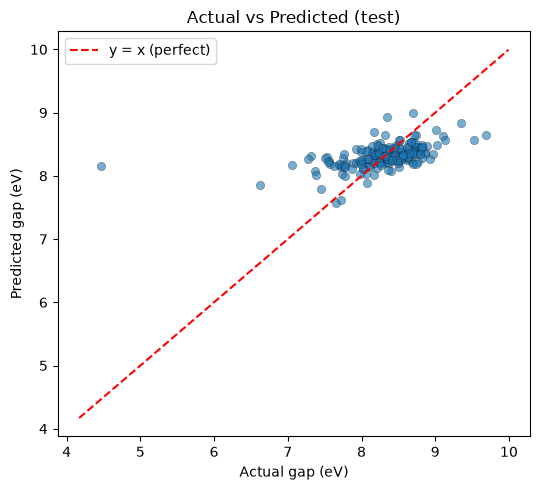

In [14]:
# ============ Fig 1: Actual vs Predicted (with reference line y=x) ============
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, y_pred_test, alpha=0.6, edgecolor="black", linewidth=0.3)
lim = [y_test.min()-0.3, y_test.max()+0.3]
ax.plot(lim, lim, "r--", label="y = x (perfect)")
ax.set_xlabel("Actual gap (eV)")
ax.set_ylabel("Predicted gap (eV)")
ax.set_title("Actual vs Predicted (test)")
ax.legend()
plt.tight_layout()
plt.show()

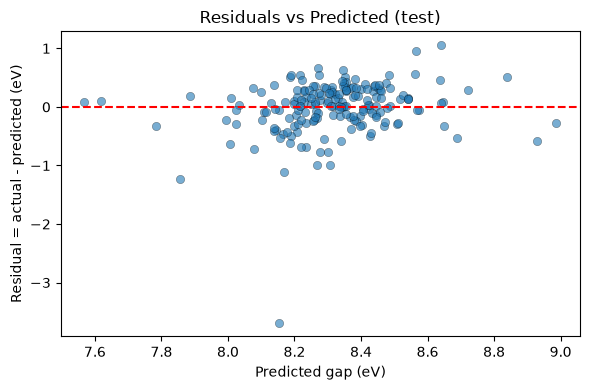

In [15]:
# ============ Fig 2: Residual vs Predicted ============
resid = y_test - y_pred_test

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(y_pred_test, resid, alpha=0.6, edgecolor="black", linewidth=0.3)
ax.axhline(0, color="r", linestyle="--")
ax.set_xlabel("Predicted gap (eV)")
ax.set_ylabel("Residual = actual - predicted (eV)")
ax.set_title("Residuals vs Predicted (test)")
plt.tight_layout()
plt.show()

In [16]:
# ============ Top-5 largest absolute test errors ============
test_eval = test.copy()
test_eval["pred"] = y_pred_test
test_eval["resid"] = resid
test_eval["abs_resid"] = resid.abs()

top5 = test_eval.nlargest(5, "abs_resid")[["id", target, "pred", "resid", "abs_resid"]]
print("=== Top-5 largest absolute errors on the test set ===")
print(top5.round(4).to_string(index=False))

=== Top-5 largest absolute errors on the test set ===
 id  HOMO_LUMO_Gap_eV   pred   resid  abs_resid
950            4.4689 8.1524 -3.6835     3.6835
489            6.6219 7.8554 -1.2335     1.2335
514            7.0510 8.1688 -1.1178     1.1178
774            9.6941 8.6400  1.0541     1.0541
482            7.3099 8.3079 -0.9980     0.9980


### Residual analysis

**MAE vs RMSE.** On the test set, MAE is 0.301 and RMSE is 0.452; RMSE is notably larger (about 1.5x MAE). Because RMSE squares the errors before taking the root, it is more sensitive to large (outlier) errors: one large residual is amplified after squaring, raising RMSE more than MAE. RMSE clearly exceeding MAE indicates that a **few large errors** inflate the overall error level, rather than all samples having a uniform moderate error. Quantitative evidence: sorting by absolute residual, the top-5 errors account for 48.6% of the test SSE, and id=950 alone accounts for 35.7%; removing id=950 lowers test RMSE from 0.452 to 0.363 and raises R2 from 0.249 to 0.317.

**Primary error source and model limitation (shrinkage toward the mean).** The mean test residual is only -0.005 and fewer than half the rows (77/186) are overestimated, so it is not accurate to say there is a "general systematic overestimation". The more accurate pattern is **shrinkage toward the mean**: the residual correlates 0.94 with the actual gap, with low-gap terciles having a mean residual of -0.40 (overestimated) and high-gap terciles +0.35 (underestimated). The model tends to pull predictions toward the mean target, under-fitting extreme samples (e.g. id=950: actual 4.47 eV, predicted 8.15 eV, error -3.68 eV). Note that although the Dummy mean model shows the same tendency to overestimate low-gap samples, the two are **mechanistically different**: Dummy outputs a constant simply because it cannot learn, whereas linear regression under-fits extreme targets under the squared-error objective.

## 9. Deliberate leakage experiment

Re-add `HOMO_eV`/`LUMO_eV`, verify the formula, compare honest vs leaky, then remove the columns from the final baseline.

In [17]:
# ============ Numerically verify Gap = LUMO - HOMO ============
computed_gap = valid["LUMO_eV"] - valid["HOMO_eV"]
actual_gap   = valid[target]
max_diff = (computed_gap - actual_gap).abs().max()
print(f"Max deviation |Gap - (LUMO - HOMO)| = {max_diff:.3e}")
print("Holds exactly?", np.allclose(computed_gap, actual_gap), "  (floating-point level; treat as exact)")

Max deviation |Gap - (LUMO - HOMO)| = 1.776e-15
Holds exactly? True   (floating-point level; treat as exact)


In [18]:
# ============ Leaky feature set: re-add HOMO_eV and LUMO_eV ============
leaky_feats = honest_feats + ["HOMO_eV", "LUMO_eV"]
print("leaky feature count:", len(leaky_feats))

# Use the same model architecture (new pipeline, feature count changed)
leaky_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression()),
])
leaky_model.fit(train[leaky_feats], y_train)
leaky_pred = leaky_model.predict(test[leaky_feats])

# ============ honest vs leaky single-table comparison ============
compare = pd.DataFrame({
    "metric": ["R²", "MAE", "RMSE"],
    "honest": [
        r2_score(y_test, y_pred_test),
        mean_absolute_error(y_test, y_pred_test),
        np.sqrt(mean_squared_error(y_test, y_pred_test)),
    ],
    "leaky": [
        r2_score(y_test, leaky_pred),
        mean_absolute_error(y_test, leaky_pred),
        np.sqrt(mean_squared_error(y_test, leaky_pred)),
    ],
}).round(4)
print("=== honest vs leaky regression (same test rows, only features differ) ===")
print(compare)

leaky feature count: 12
=== honest vs leaky regression (same test rows, only features differ) ===
  metric  honest  leaky
0     R²  0.2494    1.0
1    MAE  0.3011    0.0
2   RMSE  0.4519    0.0


### Leakage experiment interpretation

**Result.** Adding `HOMO_eV`/`LUMO_eV` changes the same test-set metrics from honest R2=0.249/MAE=0.301/RMSE=0.452 to leaky R2=1.0/MAE=0.0/RMSE=0.0. Numerical verification of `Gap = LUMO - HOMO` gives a maximum deviation of 1.776e-15, i.e. exactly satisfied.

**This perfect score is feature-level leakage, not generalization.** The leaky model is also fit only on the training set, so its R2=1.0 is not from memorizing the test rows; and since linear regression solves a weighted combination `y = w*x + b`, the model does not literally embed the formula either. Because `LUMO_eV`/`HOMO_eV` determine the target exactly, the squared-error objective drives the model toward weights approximating `LUMO - HOMO` (LUMO weight~+1, HOMO weight~-1, others~0, intercept~0), yielding zero error on any unseen sample. **The leakage lies in the features, not in the data split**: in a real prediction we do not know a new polymer's band gap in advance, so no corresponding HOMO/LUMO input would be available. This R2=1.0 therefore has no generalization meaning for real new-material prediction, and the two columns must be removed from the final baseline.

In [19]:
# ============ Final honest-baseline confirmation ============
print("Final honest feature count:", len(honest_feats))
print("Honest features:", honest_feats)
print("\nConfirm HOMO_eV / LUMO_eV are NOT in honest features:",
      ("HOMO_eV" not in honest_feats) and ("LUMO_eV" not in honest_feats))

# Final honest-regression main test metrics (for comparison with dummy)
final_r2  = r2_score(y_test, y_pred_test)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"\nHonest regression test R2 = {final_r2:.4f}, test RMSE = {final_rmse:.4f}")
print("(cf. Day 1: dummy test R2~0, RMSE~0.52; honest regression clearly better)")

Final honest feature count: 10
Honest features: ['Energy_Hatree', 'es', 'Isotropic_Polarizability_au', 'Inner_energy_correction_Hatree', 'Thermal_correction_to_Enthalpy_Hatree', 'Thermal_correction_to_Gibbs_Free_Energy_Hatree', 'Entropy_Hatree', 'Dipole_Debye', 'Gibbs_Free_Energy_Hatree', 'Enthalpy_Hatree']

Confirm HOMO_eV / LUMO_eV are NOT in honest features: True

Honest regression test R2 = 0.2494, test RMSE = 0.4519
(cf. Day 1: dummy test R2~0, RMSE~0.52; honest regression clearly better)


## 10. Honest logistic-regression classification evaluation

Use `StandardScaler + LogisticRegression` to predict `high_gap` (positive class = 1); evaluate with 5-fold `StratifiedKFold` plus the test set.

In [20]:
# ============ Logistic-regression pipeline ============
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000)),
])
clf.fit(X_train, y_train_cls)
print("Convergence iterations (per class):", clf.named_steps["lr"].n_iter_, " <= max_iter=2000 -> converged")

# ============ 5-fold StratifiedKFold CV (training set only) ============
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1  = cross_val_score(clf, X_train, y_train_cls, cv=skf, scoring="f1")
cv_auc = cross_val_score(clf, X_train, y_train_cls, cv=skf, scoring="roc_auc")

print("\n=== 5-fold StratifiedKFold (training set only) ===")
print("Per-fold F1 :", [round(v,4) for v in cv_f1])
print(f"F1  mean: {cv_f1.mean():.4f}  std: {cv_f1.std():.4f}")
print("Per-fold AUC:", [round(v,4) for v in cv_auc])
print(f"AUC mean: {cv_auc.mean():.4f}  std: {cv_auc.std():.4f}")

Convergence iterations (per class): [14]  <= max_iter=2000 -> converged

=== 5-fold StratifiedKFold (training set only) ===
Per-fold F1 : [np.float64(0.7297), np.float64(0.7114), np.float64(0.6939), np.float64(0.7333), np.float64(0.7867)]
F1  mean: 0.7310  std: 0.0312
Per-fold AUC: [np.float64(0.7927), np.float64(0.7885), np.float64(0.7993), np.float64(0.8024), np.float64(0.8075)]
AUC mean: 0.7981  std: 0.0068


In [21]:
# ============ Fit on all training rows + evaluate on the test set ============
clf.fit(X_train, y_train_cls)
proba_tr = clf.predict_proba(X_train)[:, 1]   # probability of the high-gap class
proba_te = clf.predict_proba(X_test)[:, 1]
yhat_tr  = clf.predict(X_train)
yhat_te  = clf.predict(X_test)

def cls_metrics(y_true, y_pred, proba):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1),
        "Recall":    recall_score(y_true, y_pred, pos_label=1),
        "F1":        f1_score(y_true, y_pred, pos_label=1),
        "ROC-AUC":   roc_auc_score(y_true, proba),
    }

cls_table = pd.DataFrame({
    "Train": cls_metrics(y_train_cls, yhat_tr, proba_tr),
    "Test" : cls_metrics(y_test_cls,  yhat_te, proba_te),
}).round(4)
print("=== Honest logistic regression: Train vs Test (positive = high_gap=1, AUC from probabilities) ===")
print(cls_table)

=== Honest logistic regression: Train vs Test (positive = high_gap=1, AUC from probabilities) ===
            Train    Test
Accuracy   0.7405  0.7204
Precision  0.7405  0.7315
Recall     0.7405  0.7745
F1         0.7405  0.7524
ROC-AUC    0.8069  0.7809


Confusion matrix (rows=true, cols=predicted):
         pred low(0)  pred high(1)
true low(0)  55        29     <- TN, FP
true high(1) 23        79     <- FN, TP


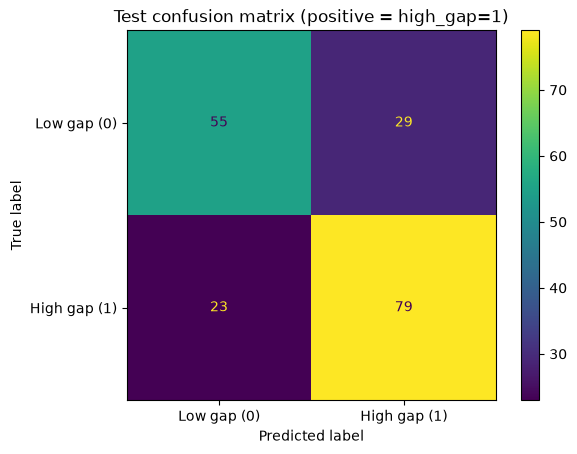

In [22]:
# ============ Labeled confusion matrix (positive = high_gap=1) ============
cm = confusion_matrix(y_test_cls, yhat_te)
print("Confusion matrix (rows=true, cols=predicted):")
print("         pred low(0)  pred high(1)")
print("true low(0)  %d        %d     <- TN, FP" % (cm[0,0], cm[0,1]))
print("true high(1) %d        %d     <- FN, TP" % (cm[1,0], cm[1,1]))

disp = ConfusionMatrixDisplay(cm, display_labels=["Low gap (0)","High gap (1)"])
disp.plot()
plt.title("Test confusion matrix (positive = high_gap=1)")
plt.show()

In [23]:
# ============ Inspect errors: FP and FN ============
# Selection rationale: for FP (true low misclassified as high), the highest-probability ones (most confident misreports) are most worth flagging;
# for FN (true high misclassified as low), we show the highest-probability ones (boundary misclassifications closest to the threshold) to examine edge samples;
# taking the lowest-probability FNs instead would correspond to 'most confident yet wrong' misses; both framings are meaningful, and the chosen one is stated here.
te_eval = test.copy()
te_eval["gap"]      = test[target].values
te_eval["true_cls"] = y_test_cls.values
te_eval["pred_cls"] = yhat_te
te_eval["proba"]    = proba_te

FP = te_eval[(te_eval["true_cls"]==0) & (te_eval["pred_cls"]==1)]  # true low predicted high
FN = te_eval[(te_eval["true_cls"]==1) & (te_eval["pred_cls"]==0)]  # true high predicted low
print(f"False positives FP: {len(FP)}   False negatives FN: {len(FN)}")

print("\n=== False positives FP (true low gap, predicted high) -- top-2 by probability (most confident misreports) ===")
print(FP.sort_values("proba", ascending=False)[["id","gap","true_cls","pred_cls","proba"]].head(2).round(4).to_string(index=False))

print("\n=== False negatives FN (true high gap, predicted low) -- top-2 by probability (boundary misclassifications) ===")
print(FN.sort_values("proba", ascending=False)[["id","gap","true_cls","pred_cls","proba"]].head(2).round(4).to_string(index=False))
print("\n=== Complement: 2 lowest-probability false negatives (most confident yet wrong) ===")
print(FN.sort_values("proba", ascending=True)[["id","gap","true_cls","pred_cls","proba"]].head(2).round(4).to_string(index=False))

False positives FP: 29   False negatives FN: 23

=== False positives FP (true low gap, predicted high) -- top-2 by probability (most confident misreports) ===
 id    gap  true_cls  pred_cls  proba
466 8.3185         0         1 0.8929
773 8.1631         0         1 0.8919

=== False negatives FN (true high gap, predicted low) -- top-2 by probability (boundary misclassifications) ===
 id    gap  true_cls  pred_cls  proba
907 8.4830         1         0 0.4907
484 8.3654         1         0 0.4834

=== Complement: 2 lowest-probability false negatives (most confident yet wrong) ===
 id    gap  true_cls  pred_cls  proba
546 8.3555         1         0 0.1518
223 8.3978         1         0 0.1521


### Classification evaluation

**Improvement over the Dummy baseline.** Compared with the Dummy classifier (prior strategy: acc~0.45, F1=0.0, AUC=0.5), the honest logistic regression improves test accuracy (0.720), F1 (0.752) and ROC-AUC (0.781). F1 rising from 0 to 0.75 shows real classification ability on both precision and recall, not just majority-class guessing; AUC well above 0.5 shows a real ability to rank high- vs low-gap samples. It must be stressed that **beating random / beating the Dummy baseline only shows the model has some learning ability - it does not mean the model is fit for real material screening**: an AUC of 0.78 is still moderate and far from a reliable predictor.

**Overfitting and stability.** Train and test metrics are close (train acc/F1/AUC: 0.7405/0.7405/0.807; test: 0.720/0.752/0.781), with no sign that training markedly outperforms testing, so **there is no obvious overfitting**. The 5-fold CV F1 std (~0.031) and AUC std (~0.007) are small, indicating stable performance across data subsets.

**The relative cost of FP vs FN depends on the use case.** The two error types cannot be weighed globally: when **screening for insulating materials**, **false positives (mistaking a low-gap, conductive material for a high-gap insulator) are costlier**, because using a conductive material as an insulator can create safety hazards whose consequences are hard to estimate in advance. When **screening for conductive materials**, a **false negative (mistaking a high-gap insulator for a low-gap conductor)** does cause a misjudgment, but re-verification in the lab is lower-risk, though it still wastes experimental resources. Hence "which error is more serious" can only be answered under an explicit application assumption.

## 11. Generalization evidence summary

In [24]:
# ============ Train vs Test target distribution (after final evaluation) ============
print("y_train.describe():")
print(y_train.describe().round(3))
print("\ny_test.describe():")
print(y_test.describe().round(3))
print(f"\nMin train: {y_train.min():.3f} | Min test: {y_test.min():.3f}")
print(f"Median train: {y_train.median():.3f} | Median test: {y_test.median():.3f}")

y_train.describe():
count    740.000
mean       8.307
std        0.471
min        6.512
25%        8.007
50%        8.332
75%        8.594
max       10.001
Name: HOMO_LUMO_Gap_eV, dtype: float64

y_test.describe():
count    186.000
mean       8.312
std        0.523
min        4.469
25%        8.089
50%        8.364
75%        8.639
max        9.694
Name: HOMO_LUMO_Gap_eV, dtype: float64

Min train: 6.512 | Min test: 4.469
Median train: 8.332 | Median test: 8.364


### Train vs Test target distribution (post-evaluation)

Comparing the target distributions of the training and test sets highlights that the minimum test gap (4.47 eV, row id=950) is well below the training range, which explains part of the regression score sensitivity to extreme rows.

```python
print(y_train.describe()); print(y_test.describe())
```

In [25]:
# ============ Summary table ============
# Regression: Day 2 results
reg_summary = pd.DataFrame({
    "set":    ["Train", "CV (mean+/-std)", "Test", "Test (leaky, rejected)"],
    "R²":      [0.2105, 0.1990, 0.2494, 1.0],
    "RMSE":    [0.4179, 0.4204, 0.4519, 0.0],
    "note":    ["honest", "R2 STD=0.027", "honest", "feature leakage"],
}).round(4)
print(reg_summary.to_string(index=False))

print("\n=== Classification summary ===\n")
print("Dummy classifier test : Accuracy~0.45, F1=0.0, AUC=0.5")
print(f"Honest logistic regression test: (see cls_table) AUC~0.781")
print(f"CV  F1 mean+/-std : {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}")
print(f"CV  AUC mean+/-std: {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")
print(f"Classification threshold: {train_median:.3f} eV | train classes {int((y_train_cls==1).sum())}:{int((y_train_cls==0).sum())}, test {int((y_test_cls==1).sum())}:{int((y_test_cls==0).sum())}")

                   set     R²   RMSE            note
                 Train 0.2105 0.4179          honest
       CV (mean+/-std) 0.1990 0.4204    R2 STD=0.027
                  Test 0.2494 0.4519          honest
Test (leaky, rejected) 1.0000 0.0000 feature leakage

=== Classification summary ===

Dummy classifier test : Accuracy~0.45, F1=0.0, AUC=0.5
Honest logistic regression test: (see cls_table) AUC~0.781
CV  F1 mean+/-std : 0.731 +/- 0.031
CV  AUC mean+/-std: 0.798 +/- 0.007
Classification threshold: 8.332 eV | train classes 370:370, test 102:84


### Generalization conclusions

**(1) Beating the Dummy baselines:** the honest regression (test R2=0.249) and the logistic-regression classifier (test AUC=0.781, F1=0.752) both clearly beat their Dummy baselines (regression R2~0; classifier AUC~0.5), so both models learn real information from the features.

**(2) Underfitting vs overfitting:** train and test metrics are close (regression train R2=0.2105 / test 0.2494; classifier train AUC=0.807 / test 0.781), with no training-far-exceeds-test pattern, so there is **no clear overfitting**. At the same time the absolute values are modest (regression R2~0.25, classifier AUC~0.78) and the training scores are also low - this is **consistent with underfitting**, but a linear model alone cannot distinguish "insufficient model capacity" from "weak intrinsic feature signal"; a more flexible model would be needed as a comparison to confirm the exact source of underfitting.

**(3) Fold stability vs sensitivity to extreme samples (two distinct points):** the 5-fold CV standard deviations are small (regression R2 std~0.027; classifier F1 std~0.031, AUC std~0.007), showing the training process is **stable** across subsets. But this does **not** mean the test score is immune to extreme samples - a single extreme test row (id=950) moves regression test R2 from 0.249 to 0.317, showing the test score is still **sensitive** to individual outliers. Fold stability and test-score sensitivity to extreme rows should be reported as two separate observations.

**(4) Evidence, not proof:** these conclusions rely on only 926 computed samples. Because the **database coverage is incomplete**, we cannot make a full inference about new-materials chemical space; a random split only resamples the same distribution and does not guarantee the model holds on genuinely new chemical families. These observations are therefore **evidence** on the current data, not **proof** about future materials.

## 12. The three critical questions

### Critical question 1: Are we solving a meaningful prediction problem?

**Target and unit of observation.** The modeling target is `HOMO_LUMO_Gap_eV` (band gap, eV); regression predicts its value and classification predicts high/low. One row is one computed polymer record.

**This is a calculation-to-calculation model.** All honest features are other computed properties (energy, polarizability, etc.), so the baseline predicts one computed quantity from other computed quantities; it is **not** a structure-to-property model that predicts properties directly from molecular structure.

**The classification threshold lacks physical meaning.** `high_gap` uses the training median (8.332 eV) and only constructs a balanced practice task; it is **not a scientifically validated physical boundary**, so the classification layer is mainly pedagogical.

**Limited practical value exists.** Although the inputs here are computed quantities, computed properties can in practice serve as **surrogates** for real physical quantities: under relaxed accuracy requirements, and once the surrogate's validity against experimental properties is verified, properties can be approximated from computed/measured data. So the model is not without practical value - but it currently remains a "calculation-to-calculation" model, still short of a deployable "structure-to-property" predictor.

### Critical question 2: Does the evaluation measure generalization rather than leakage or memory?

Yes. The evaluation pipeline protects against leakage and memorization on multiple fronts:

**(1) Test-set isolation.** The test rows never participate in preprocessing, model selection, or any decision, and are evaluated only once after the workflow is fixed.

**(2) Preprocessing inside the pipeline.** `StandardScaler` is refit on the training portion within every CV fold, so validation/test data never join the fit; this prevents statistical leakage.

**(3) Judging leakage with a controlled experiment (strongest evidence).** Rather than guessing, we deliberately re-added `HOMO_eV`/`LUMO_eV`, measured test R2=1.0, and numerically verified `Gap=LUMO-HOMO` (max deviation 1.8e-15). This control lets us see what happens when the features carry the answer, so we can identify and reject the fake high score produced by leakage - and conversely confirm that the honest 0.249 is not such a leakage artifact.

**(4) Stability across folds.** Regression CV R2~0.199 vs test 0.249, and classifier CV AUC~0.80 vs test 0.78, are close, with small fold standard deviations, so the results are not an artifact of a single split.

**(5) Clearly beating Dummy.** Both regression and classification exceed baselines that output only the mean/majority class, showing the models learn real relationships rather than memorizing training statistics.

**Conclusion:** together these justify that the evaluation measures generalization - in particular, the leakage control experiment lets us distinguish "true generalization" from "fake high scores caused by feature leakage".

### Critical question 3: What do the scores say - and what do they hide?

**Different metrics view the same predictions from different angles.** MAE and RMSE describe regression error: RMSE, by squaring before taking the root, is more sensitive to large errors and so tends to exceed MAE (test 0.452 vs 0.301), hinting at a few large errors. On the classification side, accuracy only reflects overall correctness and is affected by class balance; F1 is a precision/recall blend at one fixed threshold; ROC-AUC measures ranking across all thresholds. The three **can disagree** because they answer different questions.

**What is optimized is not what is reported.** Logistic regression is trained to minimize cross-entropy (log loss), yet we report and score it with accuracy/F1/AUC. That is, **the objective the model is trained to optimize differs from the criterion we use to evaluate it**; these external metrics do not reflect the model's internal mechanism - they only probe it by feeding test samples and reading the predictions. **Because of this, external evaluation loses and simplifies internal detail and carries information loss and bias; a single number should not be trusted as complete.**

**Metrics must be combined and read critically.** Although these metrics are practically useful for judging a model, any single accuracy/F1/AUC is biased in its own way and should not be used alone; they should be **combined**, and even then the evaluation method itself can still be improved.

## 13. Codex review

Codex was asked to review the three notebooks on five dimensions: target/preprocessing leakage, test-set misuse, metric-calculation errors, unsupported bias/variance/scientific claims, and reproducibility. The accept/revise decisions below were based on rechecking the data rather than accepting the output verbatim.

**Accepted suggestion: fix the "general systematic overestimation" and "conclusion not affected by few samples" claims.** Codex noted both statements exceeded the evidence. Verification: the mean test residual is only -0.005, fewer than half the rows are overestimated (77/186), and the true pattern is **shrinkage toward the mean** (residual-actual-gap correlation 0.94; low-gap tercile mean residual -0.40, high-gap tercile +0.35); moreover a single extreme test row (id=950) moves regression test R2 from 0.249 to 0.317. The conclusion was rewritten accordingly and "fold stability" was separated from "sensitivity of the test score to extreme samples".

**Retained, with clarified rationale and an added complementary perspective: the FN inspection selection logic.** Codex suggested selecting FNs with the lowest probability (most confident yet wrong). On rechecking, we keep the highest-probability FNs (boundary misclassifications closest to the threshold) as the primary view - because they expose the model's uncertainty at the fuzzy boundary, in contrast with the "most confident false positives" on the FP side - and additionally show the lowest-probability FNs as a complementary view, presenting both rather than only one. This is a **conditional acceptance**: we accept the criticism that the rationale should be explicit, and keep our own choice of which misclassification type to highlight.

**(Additional) a numerical claim confirmed rather than rejected:** Codex stated the top-5 errors account for 48.6% of test SSE. Independent verification (sorting by absolute residual) confirms 48.6% (of which id=950 alone is 35.7%), so rather than rejecting it, we adopt it as the quantitative evidence for the "few large errors" argument.

**Overall verdict (Codex's evaluation, accepted by us):** there are no hard defects in code or metrics; regression/classification metrics, AUC-from-probabilities, positive-class consistency, within-CV scaling, and the training-median threshold were all rechecked and are correct, so the baselines can be submitted. Responsibility for the final conclusions remains with the experiment's author.